# Gradient boosting for classification

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train a gradient boosting machine to predict which clients subscribe to a term deposit. We first change the loss function, the learning rate and the depth of the trees, one at a time, and we use what we learn to narrow down the hyperparameter search. Then, we see that many combinations of hyperparameters return models that perform equally well.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split

### Load data

We use the bank marketing data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/bank_marketing.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [3]:
# the trees from Scikit-learn take numbers, so we replace the categories by integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].apply(lambda var: var.astype("category").cat.codes)

# GradientBoostingClassifier does not take missing values.
# For now, we replace NaN by a value outside the distribution.
df = df.fillna(-1)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1.0,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1.0,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1.0,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1.0,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1.0,0,3,0


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="y"),
    df["y"],
    test_size=0.3,
    stratify=df["y"],
    random_state=0,
)

X_train.shape, X_test.shape

((31647, 16), (13564, 16))

In [5]:
# the fraction of clients that subscribe to the term deposit
y_train.mean(), y_test.mean()

(np.float64(0.11697791259835055), np.float64(0.1170008846947803))

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on.

In [6]:
gbm = GradientBoostingClassifier(
    # the ensemble
    n_estimators=100,
    learning_rate=0.1,
    loss="log_loss",
    subsample=1.0,
    max_features=None,

    # how far each tree grows
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_leaf_nodes=None,
    min_impurity_decrease=0.0,
    ccp_alpha=0.0, # pruning

    # early stopping and training in steps
    n_iter_no_change=None,
    validation_fraction=0.1,
    tol=0.0001,
    warm_start=False,

    # reproducibility
    random_state=0,
)

gbm.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (imp

In [7]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        balanced_accuracy = balanced_accuracy_score(y, model.predict(X))
        roc_auc = roc_auc_score(y, model.predict_proba(X)[:, 1])
        print(f"{name} balanced accuracy: {balanced_accuracy:.4f}, roc-auc: {roc_auc:.4f}")


evaluate(gbm, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.6984, roc-auc: 0.9310
test balanced accuracy: 0.6774, roc-auc: 0.9212


With the default parameters, the model reaches a roc-auc of 0.92 in the test set, and the performance in the train and test sets is similar, so 100 trees of depth three do not overfit this data.

The balanced accuracy is much lower than the roc-auc, because only 12% of the clients subscribe, and with the default threshold of 0.5, the model misses many of them. The roc-auc tells us how well the model ranks the clients, independently of the threshold, so we use it to compare the models in the rest of the notebook.

### The loss function

`GradientBoostingClassifier` supports two loss functions. The log loss, which is the default, is the same loss that we minimise in logistic regression.

We train one model with each loss, and we evaluate the ensemble after each new tree with `staged_predict_proba`.

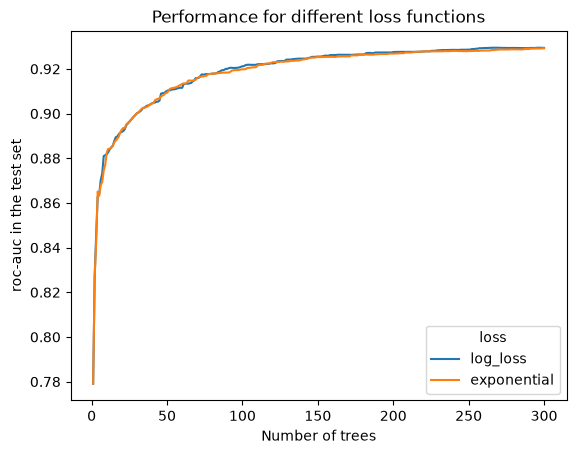

In [8]:
losses = ["log_loss", "exponential"]

curves = {}
for loss in losses:
    model = GradientBoostingClassifier(n_estimators=300, loss=loss, random_state=0)
    model.fit(X_train, y_train)
    curves[loss] = [roc_auc_score(y_test, p[:, 1]) for p in model.staged_predict_proba(X_test)]

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("roc-auc in the test set")
plt.title("Performance for different loss functions")
plt.legend(title="loss")
plt.show()

In [9]:
# the performance after 100 and 300 trees
curves.loc[[100, 300]].round(4)

,log_loss,exponential
100,0.9212,0.9198
300,0.9294,0.9292


The two losses return practically the same model. There is nothing to gain from searching over the loss, so we keep the log loss, which is the default.

### The learning rate

The learning rate multiplies the contribution of each tree, so with a small learning rate every tree corrects only a small part of the error, and we need more trees to reach the same performance.

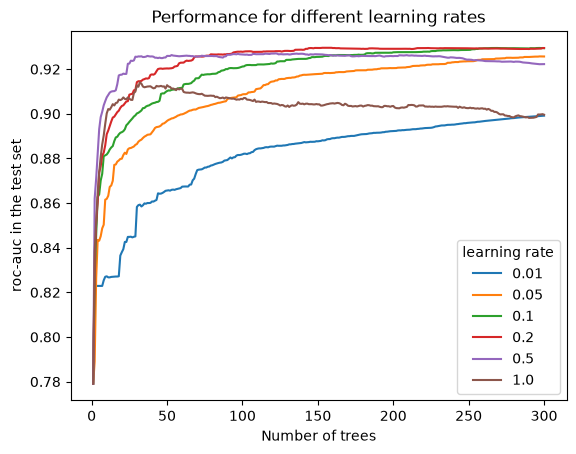

In [10]:
learning_rates = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0]

curves = {}
for learning_rate in learning_rates:
    model = GradientBoostingClassifier(n_estimators=300, learning_rate=learning_rate, random_state=0)
    model.fit(X_train, y_train)
    curves[learning_rate] = [roc_auc_score(y_test, p[:, 1]) for p in model.staged_predict_proba(X_test)]

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("roc-auc in the test set")
plt.title("Performance for different learning rates")
plt.legend(title="learning rate")
plt.show()

In [11]:
# the best roc-auc of each model, and the number of trees where we find it
pd.DataFrame({"best roc-auc": curves.max(), "number of trees": curves.idxmax()}).round(4)

,best roc-auc,number of trees
0.01,0.8992,300
0.05,0.9257,297
0.10,0.9295,268
0.20,0.9296,158
0.50,0.9271,122
1.00,0.9141,32


With a learning rate of 0.01, the model is still learning after 300 trees, and with 0.05, it is close to its best but still improving. Learning rates of 0.1 and 0.2 return the best models, and 0.2 gets there with fewer trees. With learning rates of 0.5 and 1, the performance peaks with few trees and then it goes down, because each tree corrects too much of the error.

### The depth of the trees

The depth of the trees decides how many features can interact in each tree. A stump, a tree of depth one, makes a single question, so it can only capture the effect of one feature at a time. Deeper trees capture interactions, but they also fit the train set faster.

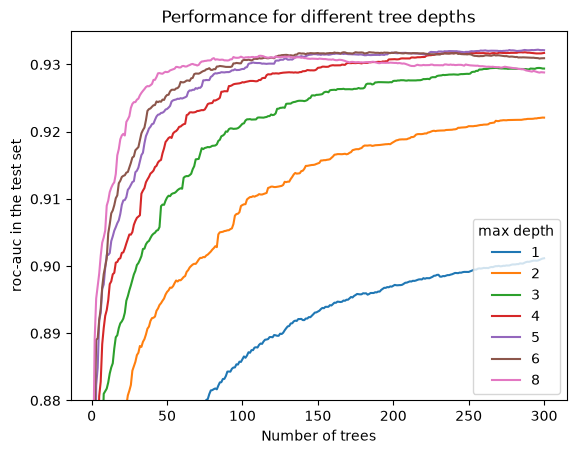

In [12]:
depths = [1, 2, 3, 4, 5, 6, 8]

curves = {}
for depth in depths:
    model = GradientBoostingClassifier(n_estimators=300, max_depth=depth, random_state=0)
    model.fit(X_train, y_train)
    curves[depth] = [roc_auc_score(y_test, p[:, 1]) for p in model.staged_predict_proba(X_test)]

curves = pd.DataFrame(curves)
curves.index = curves.index + 1

curves.plot()
plt.xlabel("Number of trees")
plt.ylim(0.88, 0.935) # we zoom into the top of the curves
plt.ylabel("roc-auc in the test set")
plt.title("Performance for different tree depths")
plt.legend(title="max depth")
plt.show()

In [13]:
# the best roc-auc of each model, and the number of trees where we find it
pd.DataFrame({"best roc-auc": curves.max(), "number of trees": curves.idxmax()}).round(4)

,best roc-auc,number of trees
1,0.9012,300
2,0.9221,299
3,0.9295,268
4,0.9318,285
5,0.9322,296
6,0.9318,184
8,0.9313,112


Stumps, which AdaBoost uses by default, are too weak for this data, and they are still improving after 300 trees. Depths between 4 and 6 return the best models. The deeper the trees, the faster the model learns: with a depth of 8, it reaches its best performance with about 100 trees, and then it starts to overfit.

## Training the gradient boosting machine

We'll take some of the best configurations from the previous result and train the machine until it does not improve performance any further.

- The two losses returned the same performance, so we keep the log loss, which is known to be more robust.
- The best learning rates were between 0.1 and 0.2. We take 0.2 so it learns faster.
- The best depths were between 4 and 6, so we take 5.

In [14]:
gbm = GradientBoostingClassifier(
    # the ensemble
    n_estimators=2000, # big, and make it stop automatically
    learning_rate=0.2,
    loss="log_loss",

    # how far each tree grows
    max_depth=5,

    # early stopping and training in steps
    n_iter_no_change=5,
    validation_fraction=0.1,
    tol=0.0001,

    # reproducibility
    random_state=0,
)

gbm.fit(X_train, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.2
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",2000
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"n_iter_no_change n_iter_no_change: int, default=None``n_iter_no_change`` is used to decide if early stopping will be usedto terminate training when validation score is not improving. Bydefault it is set to None to disable early stopping. If set to anumber, it will set aside ``validation_fraction`` size of the trainingdata as validation and terminate training when validation score is notimproving in all of the previous ``n_iter_no_change`` numbers ofiterations. The split is stratified.Values must be in the range `[1, inf)`.See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_early_stopping.py`... versionadded:: 0.20",5
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`

In [15]:
gbm.n_estimators_

34

In [16]:
evaluate(gbm, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.7423, roc-auc: 0.9463
test balanced accuracy: 0.7005, roc-auc: 0.9254


## Optimising the gradient boosting machine

We use what we learned to set up the search:

- The two losses returned the same performance, so we keep the log loss, which is the default, and we don't search over it.
- The best learning rates were between 0.1 and 0.2.
- The best depths were between 4 and 6, so we search between 3 and 6.

Because the ranges are narrow, we can afford to try all the combinations with a grid search, and this lets us plot the performance against each hyperparameter. We leave the number of trees fixed at 300.

In [17]:
param_grid = {
    "learning_rate": [0.1, 0.2],
    "max_depth": [4, 5, 6],
}

search = GridSearchCV(
    GradientBoostingClassifier(n_estimators=300, loss="log_loss", random_state=0),
    param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

search.fit(X_train, y_train)

search.best_params_

{'learning_rate': 0.1, 'max_depth': 4}

In [18]:
# the standard deviation tells us how much the metric changes across the folds
results = pd.DataFrame(search.cv_results_)
results = results.sort_values("rank_test_score")

results[["param_learning_rate", "param_max_depth", "mean_test_score", "std_test_score", "rank_test_score"]].head(10).round(4)

,param_learning_rate,param_max_depth,mean_test_score,std_test_score,rank_test_score
0,0.1,4,0.9325,0.0050,1
1,0.1,5,0.9322,0.0043,2
2,0.1,6,0.9319,0.0040,3
3,0.2,4,0.9301,0.0043,4
4,0.2,5,0.9288,0.0039,5
5,0.2,6,0.9266,0.0040,6


### Performance against the hyperparameters

We plot the mean roc-auc across the folds for each combination of hyperparameters, sorted from the best to the worst, and we show the mean plus and minus one standard deviation as a shaded area. The dashed line is the mean of the best model minus its standard deviation.

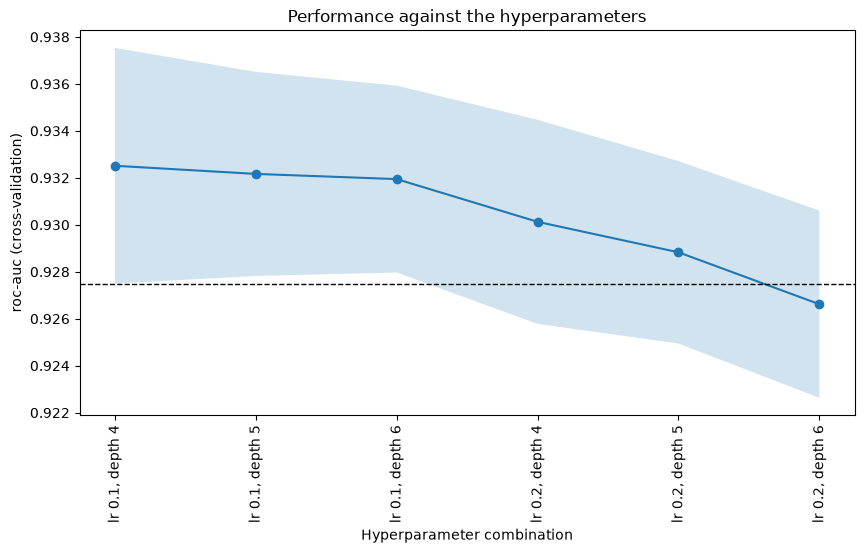

In [19]:
best = results.iloc[0]
threshold = best["mean_test_score"] - best["std_test_score"]

combinations = [
    f"lr {learning_rate}, depth {max_depth}"
    for learning_rate, max_depth in zip(results["param_learning_rate"], results["param_max_depth"])
]
x = np.arange(len(results))
mean = results["mean_test_score"]
std = results["std_test_score"]

plt.figure(figsize=(10, 5))
plt.plot(x, mean, marker="o")
plt.fill_between(x, mean - std, mean + std, alpha=0.2)
plt.axhline(threshold, color="black", linestyle="--", linewidth=1)
plt.xticks(x, combinations, rotation=90)
plt.xlabel("Hyperparameter combination")
plt.ylabel("roc-auc (cross-validation)")
plt.title("Performance against the hyperparameters")
plt.show()

Various hyperparameter combinations return models with similar performance: their error bars overlap. Hence, it makes sense to pick one set of hyperparameters among the best ones, and grow the ensemble until it learns no further, instead of testing various combinations as we did in previous videos.

In [20]:
evaluate(search.best_estimator_, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.7833, roc-auc: 0.9598
test balanced accuracy: 0.7148, roc-auc: 0.9317


The best model of the search improves the roc-auc in the test set from 0.921 to 0.933, and the balanced accuracy from 0.68 to 0.73. The gap between the train and the test set is now larger, because the trees are deeper.